# Part 2 — Data preparation + LoRA fine-tuning (Stable Diffusion 1.5, Naruto BLIP captions)
**Colab:** Runtime → T4 GPU → Run all. One run does everything: data preparation (2.1), the 20 prompts,
two LoRA runs (2.2), the training table, loss curves, a quick generation check and the push to Hugging Face.

Where files go:
- **Google Drive** (`MyDrive/DATA266_Lab2/p2/`): the 512×512 train/test images, checkpoints, LoRA weights,
  training logs and generated images. Training reads the images from there.
- **Drive-synced repo** (`Lab2/outputs/p2/`, `Lab2/eval/`): small results for the report — counts, tables,
  loss CSVs, figures, the split and the prompts.

Training saves a checkpoint every `CKPT_EVERY` steps and resumes from the last one, and a finished run is
skipped, so Run all is safe to repeat after a disconnect.
The runtime disconnects itself when the run finishes or any cell fails (`AUTO_DISCONNECT`).

In [1]:
# Cell 1 - run information (required)
NOTEBOOK_VERSION = "p2-train-v4 2026-11-11: two LoRA runs at 5000 steps; peak memory measured during the training loop"
import os, subprocess, sys, random, numpy as np, torch
IN_COLAB = os.path.exists("/var/colab/hostname")
LAB2 = "/content/drive/Othercomputers/My Mac/data266-9067/Lab2"   # Drive-synced copy of this repo's Lab2/
AUTO_DISCONNECT = True   # release the GPU when the run ends or any cell errors (Colab only)
if IN_COLAB:
    from google.colab import drive, runtime
    drive.mount("/content/drive")
    os.chdir(f"{LAB2}/notebooks")
    def _disconnect_on_error(shell, etype, evalue, tb, tb_offset=None):
        shell.showtraceback((etype, evalue, tb), tb_offset=tb_offset)
        if AUTO_DISCONNECT:
            print("Stopped - disconnecting the GPU runtime."); runtime.unassign()
    get_ipython().set_custom_exc((Exception,), _disconnect_on_error)
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True,
text=True).stdout.strip()
print({"version": NOTEBOOK_VERSION, "commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})

Mounted at /content/drive
{'version': 'p2-train-v4 2026-11-11: two LoRA runs at 5000 steps; peak memory measured during the training loop', 'commit': '49bacd3', 'python': '3.13.16', 'torch': '2.14.1+cu130', 'gpu': 'NVIDIA L4', 'seed': 266}


In [2]:
# Paths and settings
import io, json, hashlib, collections
from pathlib import Path
from PIL import Image, ImageOps
import datasets, PIL
from datasets import load_dataset
from huggingface_hub import HfApi

DATASET = "lambdalabs/naruto-blip-captions"
RES = 512                       # SD 1.5 resolution
TEST_FRACTION = 0.10
NEAR_DUP_MAX_BITS = 2           # two images are near-duplicates if their 64-bit dHashes differ in <= this many bits
EVAL_DIR = Path("../eval"); OUT_DIR = Path("../outputs/p2"); OUT_DIR.mkdir(parents=True, exist_ok=True)   # small, synced
DRIVE = Path("/content/drive/MyDrive/DATA266_Lab2/p2") if IN_COLAB else Path("../outputs/p2_drive")       # heavy files
DATA_ROOT = DRIVE / "data"; RUNS_ROOT = DRIVE / "runs"
for d in (DATA_ROOT, RUNS_ROOT): d.mkdir(parents=True, exist_ok=True)
SPLIT_FILE = EVAL_DIR / "p2_split.json"
PROMPTS_FILE = EVAL_DIR / "p2_prompts.csv"

# Training settings: both runs use the same data, steps, batch size and learning rate; only the rank changes
BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
# v3 trained both ranks for 1500 steps (runs/run1_lora_r4, runs/run2_lora_r32, kept on Drive): the style effect was
# weak, so v4 trains both for 5000 steps under new names. The diffusers Naruto example uses 15000 steps.
MAX_STEPS = 5000                # optimizer steps per run
RUNS = [{"name": f"run1_lora_r4_s{MAX_STEPS}", "rank": 4}, {"name": f"run2_lora_r32_s{MAX_STEPS}", "rank": 32}]
BATCH, GRAD_ACCUM = 1, 4        # 4 images per optimizer step
LR = 1e-4
CKPT_EVERY = 500
PUSH_TO_HF = True               # needs a Colab secret named HF_TOKEN with write access; repos are created private
print({"datasets": datasets.__version__, "pillow": PIL.__version__, "drive": str(DRIVE), "runs": RUNS,
       "steps": MAX_STEPS, "batch": BATCH, "grad_accum": GRAD_ACCUM, "lr": LR})

{'datasets': '4.8.5', 'pillow': '11.3.0', 'drive': '/content/drive/MyDrive/DATA266_Lab2/p2', 'runs': [{'name': 'run1_lora_r4_s5000', 'rank': 4}, {'name': 'run2_lora_r32_s5000', 'rank': 32}], 'steps': 5000, 'batch': 1, 'grad_accum': 4, 'lr': 0.0001}


In [3]:
# diffusers + its LoRA training script from the same release
import importlib.util, urllib.request
if importlib.util.find_spec("diffusers") is None or importlib.util.find_spec("peft") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "diffusers", "peft"], check=True)
if importlib.util.find_spec("torchao") is not None:
    # Colab ships an old torchao; peft then refuses to create LoRA layers ("incompatible version of torchao").
    # Nothing here uses torchao, so it is removed for this session.
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=True)
    importlib.invalidate_caches(); print("Removed torchao for this session.")
import diffusers, peft, transformers, accelerate
TRAIN_SCRIPT = Path("/content/train_text_to_image_lora.py") if IN_COLAB else OUT_DIR / "train_text_to_image_lora.py"
SCRIPT_URL = (f"https://raw.githubusercontent.com/huggingface/diffusers/v{diffusers.__version__}"
              "/examples/text_to_image/train_text_to_image_lora.py")
urllib.request.urlretrieve(SCRIPT_URL, TRAIN_SCRIPT)
print({"diffusers": diffusers.__version__, "peft": peft.__version__, "transformers": transformers.__version__,
       "accelerate": accelerate.__version__, "script": SCRIPT_URL,
       "script_sha256": hashlib.sha256(TRAIN_SCRIPT.read_bytes()).hexdigest()[:16]})

Removed torchao for this session.
{'diffusers': '0.42.1', 'peft': '0.21.2', 'transformers': '5.22.1', 'accelerate': '1.15.0', 'script': 'https://raw.githubusercontent.com/huggingface/diffusers/v0.42.1/examples/text_to_image/train_text_to_image_lora.py', 'script_sha256': '7d67f3ed756a3cb7'}


## 2.1 Load the dataset, remove corrupted and duplicate images (report counts)
- **Corrupted:** the image does not decode, is smaller than 64 px on a side, or has an empty caption.
- **Exact duplicate:** same MD5 of the image file bytes as an earlier row.
- **Near-duplicate:** 64-bit difference hash (dHash) within `NEAR_DUP_MAX_BITS` bits of an earlier kept row.

The first image of each duplicate group is kept. Duplicates are removed **before** the split, so the same
image cannot be in both train and test.

In [4]:
# Load (the dataset revision is pinned so the split can be reproduced)
split_saved = json.loads(SPLIT_FILE.read_text()) if SPLIT_FILE.exists() else None
REVISION = split_saved["revision"] if split_saved else HfApi().dataset_info(DATASET).sha
raw = load_dataset(DATASET, split="train", revision=REVISION)
raw_bytes = raw.cast_column("image", datasets.Image(decode=False))   # file bytes, for hashing and decode checks
print({"dataset": DATASET, "revision": REVISION, "rows": len(raw), "columns": raw.column_names})

README.md:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/897 [00:00<?, ?B/s]

data/train-00000-of-00002-12944970063701(…): reconstructing file:   0%|          |  0.00B /  344MB            

data/train-00000-of-00002-12944970063701(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-cefa2f480689f1(…): reconstructing file:   0%|          |  0.00B /  357MB            

data/train-00001-of-00002-cefa2f480689f1(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1221 [00:00<?, ? examples/s]

{'dataset': 'lambdalabs/naruto-blip-captions', 'revision': '1ed13e8ef280bd45e3bbac4cfa8bbd9d64ec9f89', 'rows': 1221, 'columns': ['image', 'text']}


In [5]:
# Find corrupted rows, exact duplicates and near-duplicates
def dhash_bits(img, size=8):
    """64-bit difference hash: grayscale, resize to 9x8, compare each pixel with its right neighbour."""
    g = np.asarray(img.convert("L").resize((size + 1, size), Image.LANCZOS), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()

corrupted, exact_dups, near_dups = [], [], []      # near_dups holds (removed_idx, kept_idx, bits)
nearest = []                                       # (bits, row, closest earlier kept row) for every kept image
seen_md5, kept, kept_hashes, orig_sizes = {}, [], [], {}
for i, row in enumerate(raw_bytes):
    data, text = row["image"]["bytes"], (row["text"] or "").strip()
    try:
        img = Image.open(io.BytesIO(data)); img.load(); img = img.convert("RGB")
        if min(img.size) < 64 or not text:
            raise ValueError("too small or empty caption")
    except Exception as e:
        corrupted.append(i); continue
    md5 = hashlib.md5(data).hexdigest()
    if md5 in seen_md5:
        exact_dups.append((i, seen_md5[md5])); continue
    h = dhash_bits(img)
    if kept_hashes:
        dist = (np.stack(kept_hashes) != h).sum(axis=1)
        j = int(dist.argmin())
        if dist[j] <= NEAR_DUP_MAX_BITS:
            near_dups.append((i, kept[j], int(dist[j]))); continue
        nearest.append((int(dist[j]), i, kept[j]))
    seen_md5[md5] = i; kept.append(i); kept_hashes.append(h); orig_sizes[i] = img.size

removed = {"corrupted": len(corrupted), "exact_duplicates": len(exact_dups), "near_duplicates": len(near_dups)}
print("Rows loaded:", len(raw))
print("Removed:", removed, "| total removed:", sum(removed.values()))
print("Rows kept:", len(kept))
nearest.sort()
print("Kept images whose closest other image is within N bits (out of 64):",
      {f"<={t}": sum(d <= t for d, _, _ in nearest) for t in (4, 6, 8, 10)}, "| closest kept pair:", nearest[0][0], "bits")

Rows loaded: 1221
Removed: {'corrupted': 0, 'exact_duplicates': 0, 'near_duplicates': 0} | total removed: 0
Rows kept: 1221
Kept images whose closest other image is within N bits (out of 64): {'<=4': 0, '<=6': 2, '<=8': 6, '<=10': 19} | closest kept pair: 5 bits


No duplicates were removed. The closest pairs that were kept are shown below: they are different images.


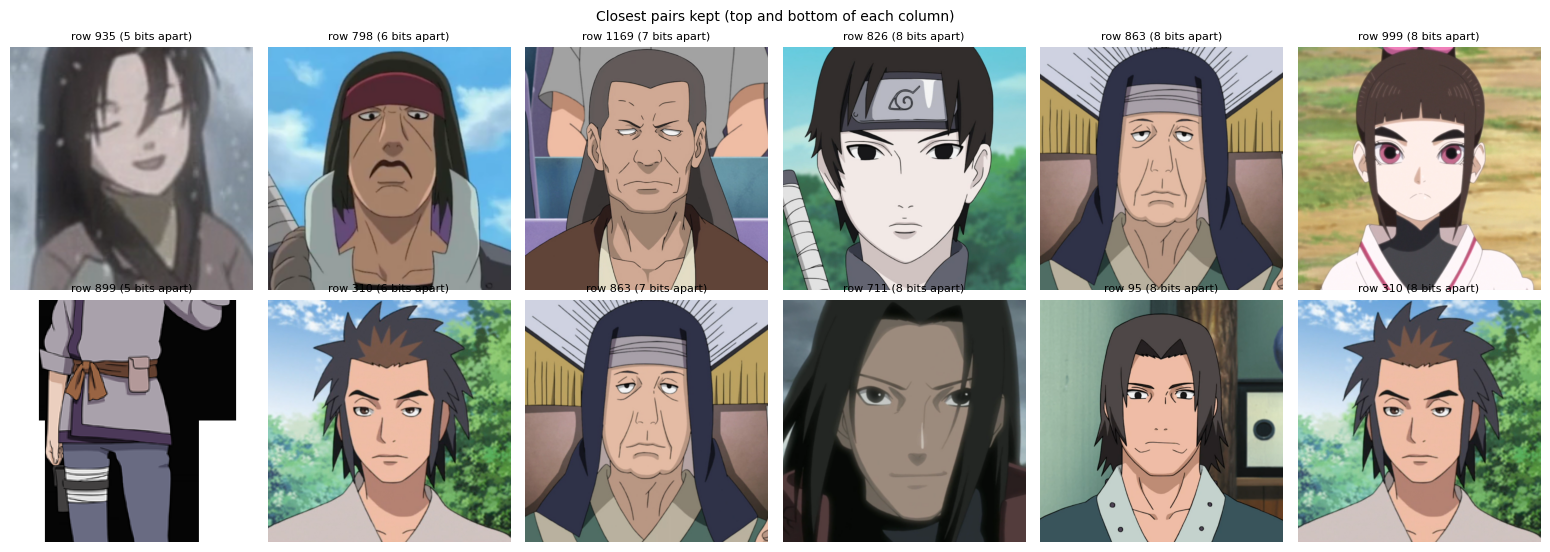

In [6]:
# Show the near-duplicate pairs that were removed (left = removed, right = the one kept), to check the threshold
import matplotlib.pyplot as plt
pairs = [(a, b, f"{d} bits") for a, b, d in near_dups] + [(a, b, "exact") for a, b in exact_dups]
if pairs:
    show = pairs[:8]
    fig, axes = plt.subplots(len(show), 2, figsize=(5, 2.5 * len(show)), squeeze=False)
    for r, (a, b, d) in enumerate(show):
        for c, idx in enumerate((a, b)):
            axes[r, c].imshow(raw[idx]["image"]); axes[r, c].axis("off")
            axes[r, c].set_title(f"row {idx} ({'removed' if c == 0 else 'kept'}, {d})", fontsize=8)
    plt.tight_layout(); plt.savefig(OUT_DIR / "duplicates_removed.png", dpi=100); plt.show()
else:
    print("No duplicates were removed. The closest pairs that were kept are shown below: they are different images.")
closest = nearest[:6]      # evidence that the threshold is not hiding duplicates
fig, axes = plt.subplots(2, len(closest), figsize=(2.6 * len(closest), 5.6), squeeze=False)
for c, (d, a, b) in enumerate(closest):
    for r, idx in enumerate((a, b)):
        axes[r, c].imshow(raw[idx]["image"]); axes[r, c].axis("off"); axes[r, c].set_title(f"row {idx} ({d} bits apart)", fontsize=8)
plt.suptitle("Closest pairs kept (top and bottom of each column)", fontsize=10); plt.tight_layout()
plt.savefig(OUT_DIR / "closest_pairs_kept.png", dpi=90); plt.show()

## 2.1 Split 90/10 (seed 266) and resize to 512×512
Test images are used only for evaluation (KID reference set and the in-domain prompts).

In [7]:
# 90/10 split with seed 266
rng = np.random.default_rng(SEED)
perm = rng.permutation(np.array(kept))
n_test = round(TEST_FRACTION * len(kept))
test_idx, train_idx = sorted(int(i) for i in perm[:n_test]), sorted(int(i) for i in perm[n_test:])
assert not set(train_idx) & set(test_idx)
print({"train": len(train_idx), "test": len(test_idx), "test_share": round(len(test_idx) / len(kept), 4)})

split = {"dataset": DATASET, "revision": REVISION, "seed": SEED, "rows_loaded": len(raw), "removed": removed,
         "removed_rows": {"corrupted": corrupted, "exact_duplicates": [a for a, _ in exact_dups],
                          "near_duplicates": [a for a, _, _ in near_dups]},
         "near_dup_max_bits": NEAR_DUP_MAX_BITS, "train_idx": train_idx, "test_idx": test_idx}
if split_saved:   # the prompts were written from the saved split, so a later run must reproduce it exactly
    assert split_saved["test_idx"] == test_idx and split_saved["train_idx"] == train_idx, \
        "This run produced a different split than eval/p2_split.json"
    print("Split matches eval/p2_split.json")
else:
    SPLIT_FILE.write_text(json.dumps(split))
    print("Wrote", SPLIT_FILE)

{'train': 1099, 'test': 122, 'test_share': 0.0999}
Split matches eval/p2_split.json


In [8]:
# Resize (shorter side to 512, centre crop) and write image folders with metadata.jsonl to Drive for the training script
import csv
def export(name, idxs):
    d = DATA_ROOT / name; d.mkdir(parents=True, exist_ok=True)
    with open(d / "metadata.jsonl", "w") as f:
        for i in idxs:
            fn = f"{i:04d}.png"
            if not (d / fn).exists():
                ImageOps.fit(raw[i]["image"].convert("RGB"), (RES, RES), Image.LANCZOS).save(d / fn)
            f.write(json.dumps({"file_name": fn, "text": raw[i]["text"].strip()}) + "\n")
    return d
TRAIN_DIR, TEST_DIR = export("train", train_idx), export("test", test_idx)
sizes = collections.Counter(Image.open(p).size for p in list(TRAIN_DIR.glob("*.png"))[:50] + list(TEST_DIR.glob("*.png"))[:50])
print({"train_dir": str(TRAIN_DIR), "train_images": len(list(TRAIN_DIR.glob('*.png'))),
       "test_dir": str(TEST_DIR), "test_images": len(list(TEST_DIR.glob('*.png'))), "sizes_checked": dict(sizes)})

with open(OUT_DIR / "test_captions.csv", "w", newline="") as f:   # the in-domain prompts are chosen from these
    w = csv.writer(f); w.writerow(["row", "caption"]); w.writerows([i, raw[i]["text"].strip()] for i in test_idx)
print("Wrote", OUT_DIR / "test_captions.csv")

{'train_dir': '/content/drive/MyDrive/DATA266_Lab2/p2/data/train', 'train_images': 1099, 'test_dir': '/content/drive/MyDrive/DATA266_Lab2/p2/data/test', 'test_images': 122, 'sizes_checked': {(512, 512): 100}}
Wrote ../outputs/p2/test_captions.csv


images_kept: 1221
train: 1099
test: 122
original_sizes_top5: [('1080x1080', 468), ('1076x1076', 135), ('1620x1620', 33), ('1050x1050', 30), ('540x540', 23)]
non_square_originals: 0
caption_words_mean: 8.9
caption_words_min: 6
caption_words_max: 41
unique_captions: 967
caption_used_by_most_images: [('a man with a sword in his hand', 35), ('a man with a gun in his hand', 12), ('two people standing next to each other people', 9)]
captions_naming_naruto: 0
subject_words: {'man': 690, 'woman': 175, 'person': 83, 'girl': 71, 'character': 46, 'group': 30, 'boy': 19}
top_words: [('man', 692), ('hair', 465), ('shirt', 193), ('white', 192), ('eyes', 181), ('long', 181), ('black', 180), ('woman', 175), ('green', 142), ('blue', 137), ('hat', 126), ('red', 115), ('brown', 95), ('sword', 86), ('person', 83), ('hand', 83), ('hoodie', 79), ('jacket', 76), ('standing', 75), ('girl', 71)]


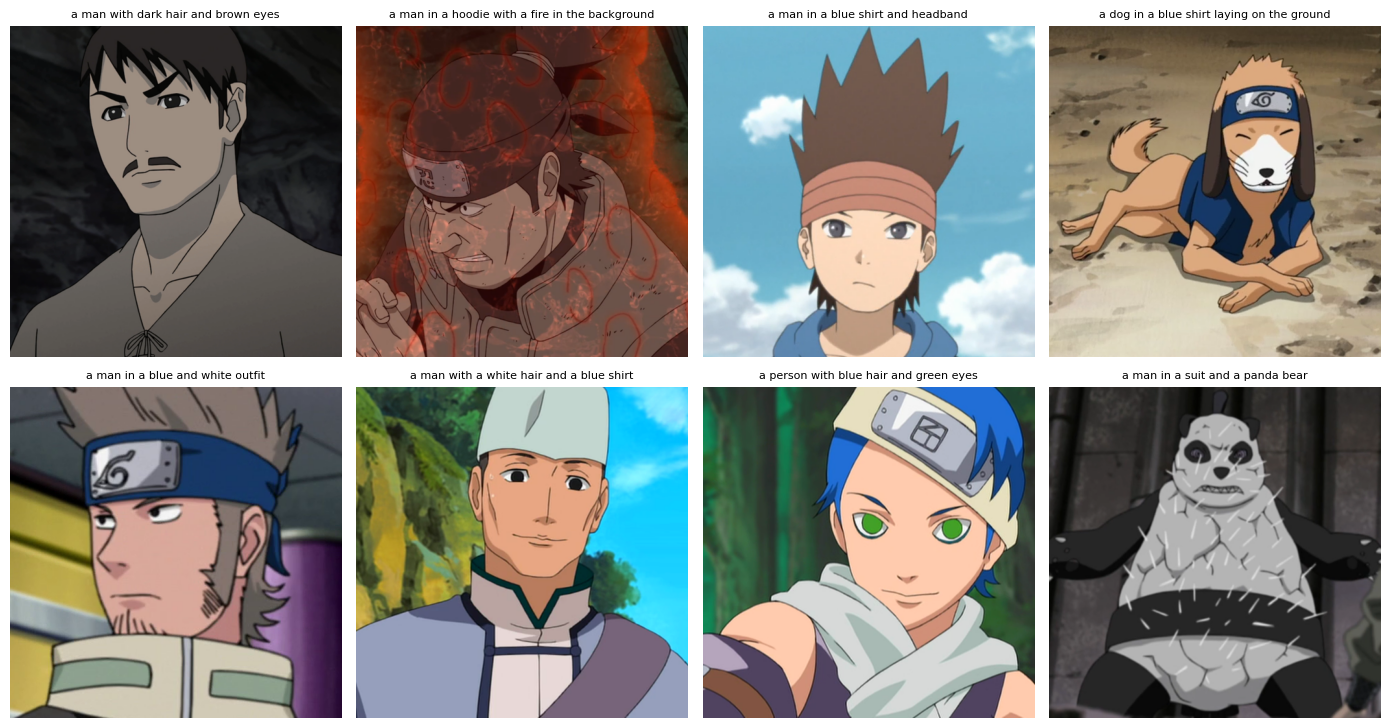

In [9]:
# Dataset description: numbers used in the text below
import re
caps = {i: raw[i]["text"].strip() for i in kept}
lens = np.array([len(c.split()) for c in caps.values()])
STOP = set("a an the of with and in on is to at his her for it he she that this are has".split())
words = collections.Counter(w for c in caps.values() for w in re.findall(r"[a-z']+", c.lower()) if w not in STOP)
size_counts = collections.Counter(orig_sizes.values())
subject = collections.Counter()
for c in caps.values():
    lc = c.lower()
    for k in ("man", "woman", "boy", "girl", "group", "couple", "person", "character"):
        if re.search(rf"\b{k}\b", lc): subject[k] += 1
stats = {"images_kept": len(kept), "train": len(train_idx), "test": len(test_idx),
         "original_sizes_top5": [(f"{w}x{h}", n) for (w, h), n in size_counts.most_common(5)],
         "non_square_originals": sum(n for (w, h), n in size_counts.items() if w != h),
         "caption_words_mean": round(float(lens.mean()), 1), "caption_words_min": int(lens.min()),
         "caption_words_max": int(lens.max()),
         "unique_captions": len(set(caps.values())),
         "caption_used_by_most_images": collections.Counter(caps.values()).most_common(3),
         "captions_naming_naruto": sum("naruto" in c.lower() for c in caps.values()),
         "subject_words": dict(subject.most_common()), "top_words": words.most_common(20)}
(OUT_DIR / "data_prep.json").write_text(json.dumps({**stats, "removed": removed, "revision": REVISION}, indent=1))
for k, v in stats.items(): print(f"{k}: {v}")

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, i in zip(axes.flat, train_idx[:8]):
    ax.imshow(Image.open(TRAIN_DIR / f"{i:04d}.png")); ax.axis("off"); ax.set_title(caps[i][:60], fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "train_samples.png", dpi=100); plt.show()

### Dataset description
_To be written from the numbers printed above after the first run (image count, sizes, caption length), with
two limitations or biases._

## 2.3 (part 1) Fix the 20 prompts before training
`eval/p2_prompts.csv` holds the 5 out-of-domain and 5 compositional prompts. The 10 in-domain prompts are
test-set captions, drawn here with seed 266 and added to the file. This cell runs before any training.

In [10]:
import pandas as pd, datetime
FIXED_PROMPTS_SHA256 = "0e87830e15ef57a9a8163f38adaf67641dee1fc80e99a29efb2f74c617ed921e"   # the 10 hand-written prompts, hashed 2026-11-12
LINEAGE_FILE = EVAL_DIR / "p2_lineage.json"
def rows_sha256(df):
    """SHA-256 of the sorted [id, type, prompt] rows, so the hash does not depend on CSV quoting or row order."""
    rows = sorted([str(r.id).strip(), str(r.type).strip(), str(r.prompt).strip()] for r in df.itertuples())
    return hashlib.sha256(json.dumps(rows, ensure_ascii=False, separators=(",", ":")).encode("utf-8")).hexdigest()
prompts = pd.read_csv(PROMPTS_FILE)
assert rows_sha256(prompts[prompts["type"] != "in_domain"]) == FIXED_PROMPTS_SHA256, \
    "the out-of-domain / compositional prompts differ from the hash recorded before training"
test_caps = sorted({raw[i]["text"].strip() for i in test_idx})
train_caps = {raw[i]["text"].strip() for i in train_idx}
if (prompts["type"] == "in_domain").sum() == 0:
    unseen = [c for c in test_caps if c not in train_caps]      # prefer captions that never appear in training
    pool = unseen if len(unseen) >= 10 else test_caps
    pick = np.random.default_rng(SEED).choice(len(pool), 10, replace=False)
    in_dom = pd.DataFrame({"id": [f"p{k + 1:02d}" for k in range(10)], "type": "in_domain",
                           "prompt": [pool[j] for j in sorted(pick)]})
    prompts = pd.concat([in_dom, prompts], ignore_index=True)
    prompts.to_csv(PROMPTS_FILE, index=False)
    print(f"Added 10 in-domain prompts from {len(pool)} candidate test captions "
          f"({len(unseen)} of {len(test_caps)} unique test captions never appear in training).")
counts = prompts["type"].value_counts().to_dict()
assert counts == {"in_domain": 10, "out_of_domain": 5, "compositional": 5}, counts
assert all(p.strip() in set(test_caps) for p in prompts[prompts["type"] == "in_domain"]["prompt"]), \
    "an in-domain prompt is not a test-set caption"
_trained = [r["name"] for r in RUNS if (RUNS_ROOT / r["name"] / "pytorch_lora_weights.safetensors").exists()]
print("20 prompts in place at", datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
      "- runs already finished:", _trained or "none (this is before any training)")
pd.set_option("display.max_colwidth", None); print(prompts.to_string(index=False))

# Lineage: hashes of the prompts and the split, checked on every run and stored with each trained model
PROMPTS_SHA256 = rows_sha256(prompts)
SPLIT_SHA256 = hashlib.sha256(json.dumps({"train": train_idx, "test": test_idx}, separators=(",", ":")).encode()).hexdigest()
lineage = json.loads(LINEAGE_FILE.read_text()) if LINEAGE_FILE.exists() else {}
now_utc = datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds")
for key, value, extra in (("all_prompts", PROMPTS_SHA256, {"rows": 20, "in_domain": "10 test captions drawn with seed 266"}),
                          ("split", SPLIT_SHA256, {"dataset": DATASET, "revision": REVISION, "seed": SEED,
                                                   "train": len(train_idx), "test": len(test_idx)})):
    if key in lineage:
        assert lineage[key]["sha256"] == value, f"{key} changed since it was first hashed ({lineage[key]['hashed_at_utc']})"
    else:
        lineage[key] = {**extra, "sha256": value, "hashed_at_utc": now_utc, "runs_finished_when_hashed": _trained}
LINEAGE_FILE.write_text(json.dumps(lineage, indent=1))
print({"fixed_prompts_sha256": FIXED_PROMPTS_SHA256[:16], "all_prompts_sha256": PROMPTS_SHA256[:16],
       "split_sha256": SPLIT_SHA256[:16], "first_hashed": lineage["all_prompts"]["hashed_at_utc"]})

20 prompts in place at 2026-11-12T04:09:53+00:00 - runs already finished: none (this is before any training)
 id          type                                                                           prompt
p01     in_domain                                              a cat that is looking at the camera
p02     in_domain                                                   a demon with a gun in his hand
p03     in_domain                                          a girl with long brown hair and glasses
p04     in_domain                                          a man in a black shirt and a black vest
p05     in_domain                              a man in a purple outfit standing in front of trees
p06     in_domain                                                 a man in a red and yellow outfit
p07     in_domain                                    a man in a white hoodie looking at the camera
p08     in_domain                                               a man with black hair and a hoodie


## 2.2 Fine-tuning: two LoRA runs
Both runs use `train_text_to_image_lora.py` from diffusers on the SD 1.5 UNet attention layers, fp16, with the
same data, steps, batch size, learning rate and seed. Run 1 uses rank 4, run 2 uses rank 32.
Peak GPU memory is the highest `nvidia-smi` reading (polled every 2 s) while the training loop runs; the table also
shows the peak including the final fp32 cast and save. Time is the wall-clock time of the training process,
added up over sessions if a run was resumed.

In [11]:
import time, shutil, re
from safetensors.torch import load_file
assert torch.cuda.is_available(), "Training needs a GPU runtime (Runtime → Change runtime type → T4 GPU)"
GPU_NAME = torch.cuda.get_device_name(0)

def _gpu_mem_mb():
    out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"],
                         capture_output=True, text=True).stdout.split()
    return int(out[0]) if out else 0

def _last_step(run_dir):
    steps = [int(p.name.split("-")[1]) for p in run_dir.glob("checkpoint-*") if p.name.split("-")[1].isdigit()]
    return max(steps, default=0)

def train_run(name, rank):
    run_dir = RUNS_ROOT / name; run_dir.mkdir(parents=True, exist_ok=True)
    meta_file, weights = run_dir / "run_meta.json", run_dir / "pytorch_lora_weights.safetensors"
    meta = json.loads(meta_file.read_text()) if meta_file.exists() else {"name": name, "rank": rank, "sessions": []}
    if weights.exists() and meta.get("finished"):
        print(f"{name}: already trained, skipping."); return meta
    cmd = [sys.executable, str(TRAIN_SCRIPT),
           "--pretrained_model_name_or_path", BASE_MODEL, "--train_data_dir", str(TRAIN_DIR),
           "--image_column", "image", "--caption_column", "text", "--resolution", str(RES), "--center_crop",
           "--random_flip", "--train_batch_size", str(BATCH), "--gradient_accumulation_steps", str(GRAD_ACCUM),
           "--max_train_steps", str(MAX_STEPS), "--learning_rate", str(LR), "--lr_scheduler", "constant",
           "--lr_warmup_steps", "0", "--rank", str(rank), "--seed", str(SEED), "--mixed_precision", "fp16",
           "--dataloader_num_workers", "2", "--output_dir", str(run_dir), "--checkpointing_steps", str(CKPT_EVERY),
           "--checkpoints_total_limit", "2", "--resume_from_checkpoint", "latest", "--report_to", "tensorboard"]
    start_step, log_file = _last_step(run_dir), run_dir / f"train_log_{int(time.time())}.txt"
    print(f"{name}: rank {rank}, starting at step {start_step} of {MAX_STEPS}. Log: {log_file}")
    # Two peaks: during the training loop (steps 1..MAX_STEPS-1, read from the progress bar), and over the whole
    # process, which also includes loading and the final fp32 cast + save. GPU memory is polled every 2 seconds.
    t0, peak, peak_loop, step, last_print = time.time(), 0, 0, 0, 0.0
    with open(log_file, "w") as lf:
        proc = subprocess.Popen(cmd, stdout=lf, stderr=subprocess.STDOUT)
        while proc.poll() is None:
            time.sleep(2); mem = _gpu_mem_mb(); peak = max(peak, mem)
            with open(log_file, "rb") as f:
                f.seek(max(0, f.seek(0, 2) - 600)); tail = f.read().decode(errors="ignore")
            found = re.findall(rf"(\d+)/{MAX_STEPS} \[", tail)
            step = int(found[-1]) if found else step
            if 0 < step < MAX_STEPS: peak_loop = max(peak_loop, mem)
            if time.time() - last_print > 300:      # one progress line every 5 minutes
                line = tail.replace("\n", "\r").split("\r")[-1].strip()[-110:]
                print(f"  [{(time.time() - t0) / 60:5.1f} min, loop peak {peak_loop} MiB, overall {peak} MiB]", line)
                last_print = time.time()
    secs = time.time() - t0
    meta["sessions"].append({"start_step": start_step, "seconds": round(secs, 1), "peak_gpu_mem_mib": peak, "peak_loop_gpu_mem_mib": peak_loop,
                             "gpu": GPU_NAME, "returncode": proc.returncode})
    meta_file.write_text(json.dumps(meta, indent=1))
    if proc.returncode != 0 or not weights.exists():
        raise RuntimeError(f"{name} failed (exit {proc.returncode}). Last log lines:\n"
                           + log_file.read_text(errors="ignore")[-3000:])
    sd = load_file(str(weights))
    meta.update(finished=True, steps=MAX_STEPS, learning_rate=LR, batch_size=BATCH, grad_accum=GRAD_ACCUM,
                trainable_params=int(sum(v.numel() for k, v in sd.items() if "lora" in k.lower())),
                adapter_mb=round(weights.stat().st_size / 2**20, 2),
                train_seconds=round(sum(x["seconds"] for x in meta["sessions"] if x["returncode"] == 0), 1),
                peak_gpu_mem_mib=max(x["peak_gpu_mem_mib"] for x in meta["sessions"] if x["returncode"] == 0),
                peak_loop_gpu_mem_mib=max(x.get("peak_loop_gpu_mem_mib", 0) for x in meta["sessions"] if x["returncode"] == 0),
                gpu=GPU_NAME, base_model=BASE_MODEL, seed=SEED, mixed_precision="fp16",
                train_images=len(train_idx), prompts_sha256=PROMPTS_SHA256, split_sha256=SPLIT_SHA256,
                dataset=DATASET, dataset_revision=REVISION, diffusers=diffusers.__version__, peft=peft.__version__)
    meta_file.write_text(json.dumps(meta, indent=1))
    shutil.copy(meta_file, OUT_DIR / f"{name}_meta.json")
    print(f"{name}: done in {secs / 60:.1f} min this session, peak {peak_loop} MiB in the loop ({peak} MiB overall), "
          f"{meta['trainable_params']:,} trainable parameters.")
    return meta

### Run 1: LoRA rank 4

In [12]:
META = {}
META[RUNS[0]["name"]] = train_run(**RUNS[0])

run1_lora_r4_s5000: rank 4, starting at step 0 of 5000. Log: /content/drive/MyDrive/DATA266_Lab2/p2/runs/run1_lora_r4_s5000/train_log_1794456593.txt
  [  0.0 min, loop peak 0 MiB, overall 3 MiB] 
  [  5.0 min, loop peak 3546 MiB, overall 3546 MiB] Steps:   6%|▋         | 313/5000 [04:20<1:03:03,  1.24it/s, lr=0.0001, step_loss=0.062]
  [ 10.1 min, loop peak 3546 MiB, overall 3546 MiB] Steps:  14%|█▎        | 687/5000 [09:22<57:59,  1.24it/s, lr=0.0001, step_loss=0.234]
  [ 15.1 min, loop peak 3546 MiB, overall 3546 MiB] Steps:  21%|██        | 1062/5000 [14:24<52:50,  1.24it/s, lr=0.0001, step_loss=0.147]
  [ 20.1 min, loop peak 3546 MiB, overall 3546 MiB] Steps:  29%|██▊       | 1437/5000 [19:25<47:44,  1.24it/s, lr=0.0001, step_loss=0.0155]
  [ 25.2 min, loop peak 3546 MiB, overall 3546 MiB] Steps:  36%|███▌      | 1810/5000 [24:27<42:44,  1.24it/s, lr=0.0001, step_loss=0.128]
  [ 30.2 min, loop peak 3546 MiB, overall 3546 MiB] Steps:  44%|████▎     | 2186/5000 [29:29<37:26,  1.25it/

### Run 2: LoRA rank 32 (same data, steps, batch size and learning rate)

In [13]:
META[RUNS[1]["name"]] = train_run(**RUNS[1])

run2_lora_r32_s5000: rank 32, starting at step 0 of 5000. Log: /content/drive/MyDrive/DATA266_Lab2/p2/runs/run2_lora_r32_s5000/train_log_1794460672.txt
  [  0.0 min, loop peak 0 MiB, overall 3 MiB] 
  [  5.0 min, loop peak 3648 MiB, overall 3648 MiB] Steps:   7%|▋         | 345/5000 [04:43<1:03:09,  1.23it/s, lr=0.0001, step_loss=0.0296]
  [ 10.1 min, loop peak 3648 MiB, overall 3648 MiB] Steps:  14%|█▍        | 713/5000 [09:45<58:22,  1.22it/s, lr=0.0001, step_loss=0.0576]
  [ 15.1 min, loop peak 3648 MiB, overall 3648 MiB] Steps:  22%|██▏       | 1080/5000 [14:46<53:37,  1.22it/s, lr=0.0001, step_loss=0.017]
  [ 20.1 min, loop peak 3648 MiB, overall 3648 MiB] Steps:  29%|██▉       | 1449/5000 [19:48<48:06,  1.23it/s, lr=0.0001, step_loss=0.057]
  [ 25.2 min, loop peak 3648 MiB, overall 3648 MiB] Steps:  36%|███▋      | 1818/5000 [24:50<43:30,  1.22it/s, lr=0.0001, step_loss=0.156]
  [ 30.2 min, loop peak 3648 MiB, overall 3648 MiB] Steps:  44%|████▎     | 2187/5000 [29:52<38:02,  1.2

## 2.2 Training table: trainable parameters, LR, steps, batch size, peak GPU memory, time

In [14]:
UNET_PARAMS = 859_520_964      # SD 1.5 UNet, for the share of parameters trained
table = pd.DataFrame([{
    "run": m["name"], "method": f"LoRA rank {m['rank']}", "trainable_params": m["trainable_params"],
    "share_of_unet_%": round(100 * m["trainable_params"] / UNET_PARAMS, 3), "learning_rate": m["learning_rate"],
    "steps": m["steps"], "batch_size": f"{m['batch_size']} x {m['grad_accum']} accumulation",
    "peak_gpu_mem_gib_training": round(m["peak_loop_gpu_mem_mib"] / 1024, 2),
    "peak_gpu_mem_gib_incl_save": round(m["peak_gpu_mem_mib"] / 1024, 2), "train_minutes": round(m["train_seconds"] / 60, 1),
    "gpu_hours": round(m["train_seconds"] / 3600, 3), "sessions": sum(x["returncode"] == 0 for x in m["sessions"]), "gpu": m["gpu"],
    "adapter_mb": m["adapter_mb"]} for m in META.values()])
table.to_csv(OUT_DIR / "training_table.csv", index=False)
print(table.T.to_string(header=False))

run                         run1_lora_r4_s5000  run2_lora_r32_s5000
method                             LoRA rank 4         LoRA rank 32
trainable_params                        797184              6377472
share_of_unet_%                          0.093                0.742
learning_rate                           0.0001               0.0001
steps                                     5000                 5000
batch_size                  1 x 4 accumulation   1 x 4 accumulation
peak_gpu_mem_gib_training                 3.46                 3.56
peak_gpu_mem_gib_incl_save                4.87                 4.96
train_minutes                             68.0                 68.6
gpu_hours                                1.133                1.143
sessions                                     1                    1
gpu                                  NVIDIA L4            NVIDIA L4
adapter_mb                                3.08                24.36


run1_lora_r4_s5000 {'logged_steps': 5000, 'mean_loss_first_100': 0.0916, 'mean_loss_last_100': 0.0868}
run2_lora_r32_s5000 {'logged_steps': 5000, 'mean_loss_first_100': 0.0905, 'mean_loss_last_100': 0.086}


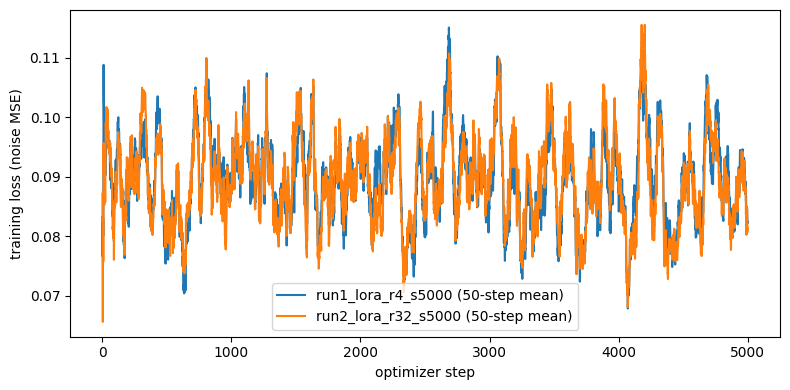

In [15]:
# Training loss per step, read from the TensorBoard logs the script wrote
try:
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
    plt.figure(figsize=(8, 4))
    for m in META.values():
        pts = {}
        for ev in sorted((RUNS_ROOT / m["name"]).rglob("events.out.tfevents.*")):
            acc = EventAccumulator(str(ev)); acc.Reload()
            if "train_loss" in acc.Tags().get("scalars", []):
                pts.update({e.step: e.value for e in acc.Scalars("train_loss")})
        loss = pd.Series(pts).sort_index()
        loss.rename_axis("step").rename("train_loss").to_csv(OUT_DIR / f"{m['name']}_loss.csv")
        plt.plot(loss.rolling(50, min_periods=1).mean(), label=f"{m['name']} (50-step mean)")
        print(m["name"], {"logged_steps": len(loss), "mean_loss_first_100": round(float(loss.iloc[:100].mean()), 4),
                          "mean_loss_last_100": round(float(loss.iloc[-100:].mean()), 4)})
    plt.xlabel("optimizer step"); plt.ylabel("training loss (noise MSE)"); plt.legend(); plt.tight_layout()
    plt.savefig(OUT_DIR / "train_loss.png", dpi=110); plt.show()
except Exception as e:
    print("Loss curves skipped:", repr(e))

## Quick check: base vs run 1 vs run 2 on two prompts
Same seed and sampler settings for the three models. The full 120-image generation and the metrics are in
`p2_generate_eval.ipynb`.

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


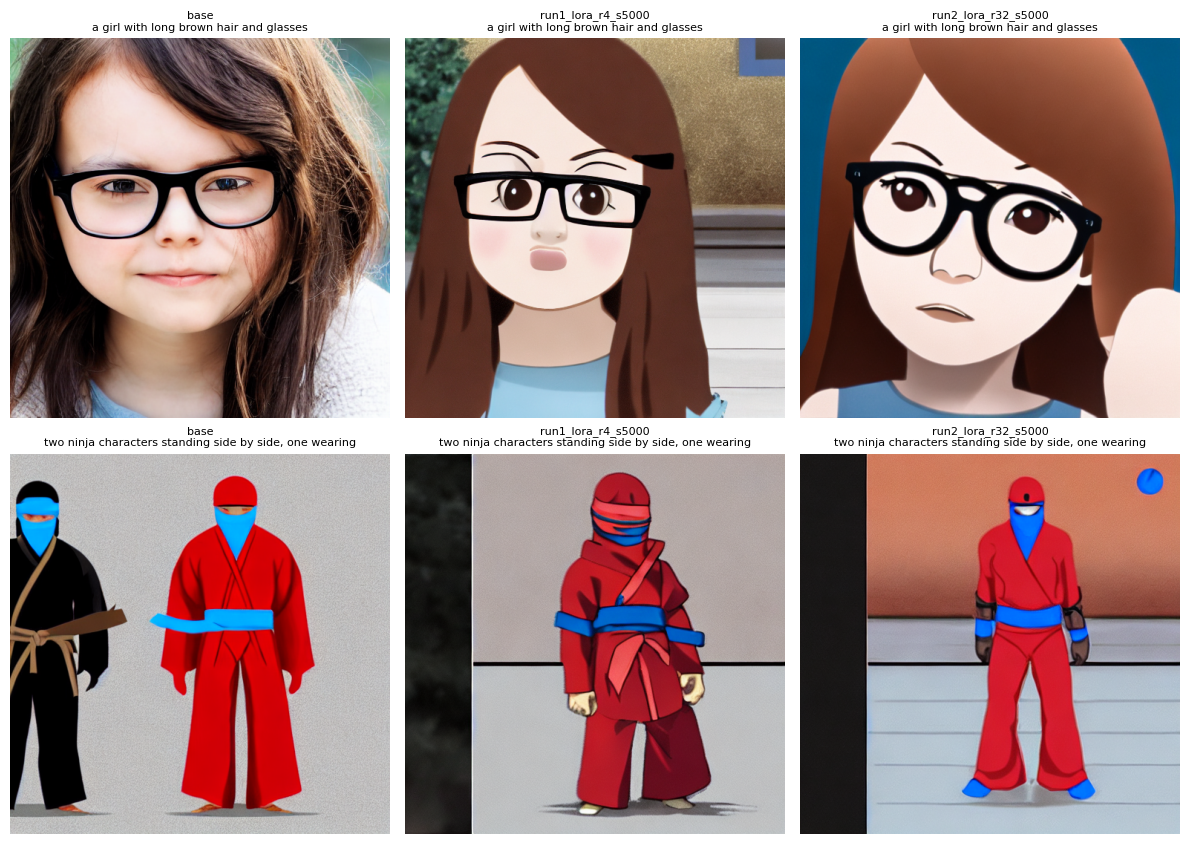

In [16]:
from diffusers import StableDiffusionPipeline
pipe = StableDiffusionPipeline.from_pretrained(BASE_MODEL, torch_dtype=torch.float16).to("cuda")   # safety checker on
pipe.set_progress_bar_config(disable=True)
_people = prompts[(prompts["type"] == "in_domain") & prompts["prompt"].str.contains(r"\b(?:man|woman|girl|boy|person)\b")]
check_prompts = [_people["prompt"].iloc[0],          # an in-domain prompt about a person, where the style should show
                 prompts[prompts["type"] == "compositional"]["prompt"].iloc[0]]
CHECK_DIR = DRIVE / "check_images"; CHECK_DIR.mkdir(parents=True, exist_ok=True)
models = ["base"] + [m["name"] for m in META.values()]
fig, axes = plt.subplots(len(check_prompts), len(models), figsize=(4 * len(models), 4.3 * len(check_prompts)), squeeze=False)
for c, model in enumerate(models):
    pipe.unload_lora_weights()
    if model != "base":
        pipe.load_lora_weights(str(RUNS_ROOT / model), weight_name="pytorch_lora_weights.safetensors")
    for r, pr in enumerate(check_prompts):
        out = pipe(pr, num_inference_steps=30, guidance_scale=7.5, generator=torch.Generator("cuda").manual_seed(0))
        out.images[0].save(CHECK_DIR / f"{model}_prompt{r}_seed0.png")
        flagged = bool(out.nsfw_content_detected and out.nsfw_content_detected[0])
        axes[r, c].imshow(out.images[0]); axes[r, c].axis("off")
        axes[r, c].set_title(f"{model}{' (NSFW flag)' if flagged else ''}\n{pr[:55]}", fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "train_check_grid.png", dpi=90); plt.show()
del pipe; torch.cuda.empty_cache()

## Push both adapters to Hugging Face
Needs a Colab secret `HF_TOKEN` with write access. The repos are created **private**; make them public (or
add the graders) before submission. The model card for the selected run is added after the evaluation.

In [17]:
if PUSH_TO_HF:
    token = os.environ.get("HF_TOKEN")
    if IN_COLAB and not token:
        try:
            from google.colab import userdata
            token = userdata.get("HF_TOKEN")
        except Exception as e:
            print("No HF_TOKEN secret:", repr(e))
    if token:
        api = HfApi(token=token); user = api.whoami()["name"]; links = {}
        for m in META.values():
            repo = f"{user}/data266-lab2-naruto-sd15-{m['name'].replace('_', '-')}"
            api.create_repo(repo, private=True, exist_ok=True)
            api.upload_folder(repo_id=repo, folder_path=str(RUNS_ROOT / m["name"]),
                              allow_patterns=["pytorch_lora_weights.safetensors", "run_meta.json"],
                              commit_message=f"{m['name']}: LoRA rank {m['rank']}, {m['steps']} steps")
            links[m["name"]] = f"https://huggingface.co/{repo}"
        (OUT_DIR / "hf_links.json").write_text(json.dumps(links, indent=1)); print(links)
    else:
        print("Not pushed: add a Colab secret HF_TOKEN (write access) and run this cell again.")

{'run1_lora_r4_s5000': 'https://huggingface.co/rahulmohannett/data266-lab2-naruto-sd15-run1-lora-r4-s5000', 'run2_lora_r32_s5000': 'https://huggingface.co/rahulmohannett/data266-lab2-naruto-sd15-run2-lora-r32-s5000'}


In [18]:
# Run finished - release the GPU (Colab)
if IN_COLAB and AUTO_DISCONNECT:
    print("Run complete - disconnecting.")
    runtime.unassign()

Run complete - disconnecting.
